# Online Shopping Spending Pattern Analysis


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

np.random.seed(42)
n = 1500

age = np.random.randint(18, 66, n)
gender = np.random.choice(["Female", "Male", "Other"], n, p=[0.48, 0.49, 0.03])
category = np.random.choice(
    ["Clothing", "Electronics", "Beauty", "Home", "Books", "Groceries"],
    n, p=[0.24, 0.18, 0.14, 0.16, 0.10, 0.18]
)
items = np.random.randint(1, 8, n)
discount = np.random.choice([0, 5, 10, 15, 20, 25, 30], n,
                            p=[0.15, 0.12, 0.20, 0.18, 0.17, 0.10, 0.08])
previous = np.random.poisson(8, n)
subscription = np.random.choice(["Yes", "No"], n, p=[0.38, 0.62])
season = np.random.choice(["Spring", "Summer", "Autumn", "Winter"], n)
payment = np.random.choice(["UPI", "Credit Card", "Debit Card", "Cash on Delivery", "Wallet"], n)
location = np.random.choice(["Metro", "Urban", "Rural"], n, p=[0.35, 0.45, 0.20])

category_base = pd.Series(category).map({
    "Clothing": 1200, "Electronics": 6500, "Beauty": 900, "Home": 2400,
    "Books": 500, "Groceries": 700
}).to_numpy()
purchase_amount = category_base * np.random.uniform(0.5, 1.6, n)
purchase_amount *= (1 - discount / 100)
purchase_amount += items * np.random.uniform(80, 250, n)
purchase_amount += np.where(subscription == "Yes", 250, 0)
purchase_amount = np.maximum(purchase_amount, 100).round(2)
review_rating = np.clip(np.random.normal(3.8, 0.8, n), 1, 5).round(1)

df = pd.DataFrame({
    "Customer_ID": [f"C{i:04d}" for i in range(1, n + 1)],
    "Age": age,
    "Gender": gender,
    "Category": category,
    "Purchase_Amount": purchase_amount,
    "Items_Purchased": items,
    "Payment_Method": payment,
    "Location": location,
    "Discount_Percent": discount,
    "Previous_Purchases": previous,
    "Subscription_Status": subscription,
    "Season": season,
    "Review_Rating": review_rating
})

# Add a few missing values and duplicate rows to demonstrate cleaning in Practical 2
for col in ["Gender", "Review_Rating", "Discount_Percent"]:
    df.loc[np.random.choice(df.index, 8, replace=False), col] = np.nan
df = pd.concat([df, df.iloc[[0, 1]]], ignore_index=True)

df.to_csv("online_shopping_spending.csv", index=False)
print("Dataset saved as online_shopping_spending.csv")
print("Shape:", df.shape)
display(df.head())

Dataset saved as online_shopping_spending.csv
Shape: (1502, 13)


,Customer_ID,Age,Gender,Category,Purchase_Amount,Items_Purchased,Payment_Method,Location,Discount_Percent,Previous_Purchases,Subscription_Status,Season,Review_Rating
0,C0001,56,Male,Electronics,7649.73,4,Wallet,Urban,20.0,7,No,Spring,3.7
1,C0002,46,Male,Books,746.68,2,Cash on Delivery,Urban,15.0,13,No,Autumn,3.6
2,C0003,32,Female,Beauty,1125.15,2,Cash on Delivery,Urban,30.0,11,No,Winter,4.3
3,C0004,60,Female,Books,1368.37,5,Debit Card,Rural,15.0,6,No,Summer,3.8
4,C0005,25,Male,Groceries,1294.68,4,Wallet,Rural,15.0,10,Yes,Summer,5.0


In [2]:
print("Dataset information:")
df.info()

print("\\nColumn names:")
print(df.columns.tolist())

print("\\nMissing values per column:")
display(df.isnull().sum().to_frame("Missing_Values"))

print("\\nDuplicate rows:", df.duplicated().sum())

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1502 entries, 0 to 1501
Data columns (total 13 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Customer_ID          1502 non-null   object 
 1   Age                  1502 non-null   int64  
 2   Gender               1494 non-null   object 
 3   Category             1502 non-null   object 
 4   Purchase_Amount      1502 non-null   float64
 5   Items_Purchased      1502 non-null   int64  
 6   Payment_Method       1502 non-null   object 
 7   Location             1502 non-null   object 
 8   Discount_Percent     1494 non-null   float64
 9   Previous_Purchases   1502 non-null   int64  
 10  Subscription_Status  1502 non-null   object 
 11  Season               1502 non-null   object 
 12  Review_Rating        1494 non-null   float64
dtypes: float64(3), int64(3), object(7)
memory usage: 152.7+ KB
\nColumn names:
['Customer_ID', 'Age', 'Gender', 'Category

,Missing_Values
Customer_ID,0
Age,0
Gender,8
Category,0
Purchase_Amount,0
Items_Purchased,0
Payment_Method,0
Location,0
Discount_Percent,8
Previous_Purchases,0


\nDuplicate rows: 2


In [3]:
# Make a clean copy
data = df.copy()

# Remove duplicate rows
data = data.drop_duplicates()

# Handle missing values
for col in data.select_dtypes(include=np.number).columns:
    data[col] = data[col].fillna(data[col].median())

for col in data.select_dtypes(include="object").columns:
    data[col] = data[col].fillna(data[col].mode()[0])

print("Shape after cleaning:", data.shape)
print("Missing values remaining:", int(data.isnull().sum().sum()))
print("Duplicate rows remaining:", int(data.duplicated().sum()))
display(data.head())
data.to_csv("online_shopping_spending_cleaned.csv", index=False)

Shape after cleaning: (1500, 13)
Missing values remaining: 0
Duplicate rows remaining: 0


,Customer_ID,Age,Gender,Category,Purchase_Amount,Items_Purchased,Payment_Method,Location,Discount_Percent,Previous_Purchases,Subscription_Status,Season,Review_Rating
0,C0001,56,Male,Electronics,7649.73,4,Wallet,Urban,20.0,7,No,Spring,3.7
1,C0002,46,Male,Books,746.68,2,Cash on Delivery,Urban,15.0,13,No,Autumn,3.6
2,C0003,32,Female,Beauty,1125.15,2,Cash on Delivery,Urban,30.0,11,No,Winter,4.3
3,C0004,60,Female,Books,1368.37,5,Debit Card,Rural,15.0,6,No,Summer,3.8
4,C0005,25,Male,Groceries,1294.68,4,Wallet,Rural,15.0,10,Yes,Summer,5.0


In [4]:
# Descriptive statistics
display(data.describe(include="all").T)

numeric_cols = ["Age", "Purchase_Amount", "Items_Purchased",
                "Discount_Percent", "Previous_Purchases", "Review_Rating"]

summary = pd.DataFrame({
    "Mean": data[numeric_cols].mean(),
    "Median": data[numeric_cols].median(),
    "Mode": data[numeric_cols].mode().iloc[0],
    "Variance": data[numeric_cols].var(),
    "Standard_Deviation": data[numeric_cols].std(),
    "Minimum": data[numeric_cols].min(),
    "Maximum": data[numeric_cols].max()
})
display(summary.round(2))

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Customer_ID,1500,1500,C1500,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,1500.0,NaN,NaN,NaN,41.587333,13.733127,18.0,29.75,42.0,53.0,65.0
Gender,1500,3,Male,730,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Category,1500,6,Clothing,347,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Purchase_Amount,1500.0,NaN,NaN,NaN,2682.2901,2128.367586,359.74,1360.33,1890.24,3101.95,11358.77
Items_Purchased,1500.0,NaN,NaN,NaN,4.042,2.016337,1.0,2.0,4.0,6.0,7.0
Payment_Method,1500,5,Wallet,356,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Location,1500,3,Urban,674,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Discount_Percent,1500.0,NaN,NaN,NaN,13.206667,9.046464,0.0,5.0,15.0,20.0,30.0
Previous_Purchases,1500.0,NaN,NaN,NaN,8.002,2.797,1.0,6.0,8.0,10.0,21.0


,Mean,Median,Mode,Variance,Standard_Deviation,Minimum,Maximum
Age,41.59,42.00,43.00,188.60,13.73,18.00,65.00
Purchase_Amount,2682.29,1890.24,1011.47,4529948.58,2128.37,359.74,11358.77
Items_Purchased,4.04,4.00,7.00,4.07,2.02,1.00,7.00
Discount_Percent,13.21,15.00,10.00,81.84,9.05,0.00,30.00
Previous_Purchases,8.00,8.00,8.00,7.82,2.80,1.00,21.00
Review_Rating,3.78,3.80,5.00,0.58,0.76,1.20,5.00


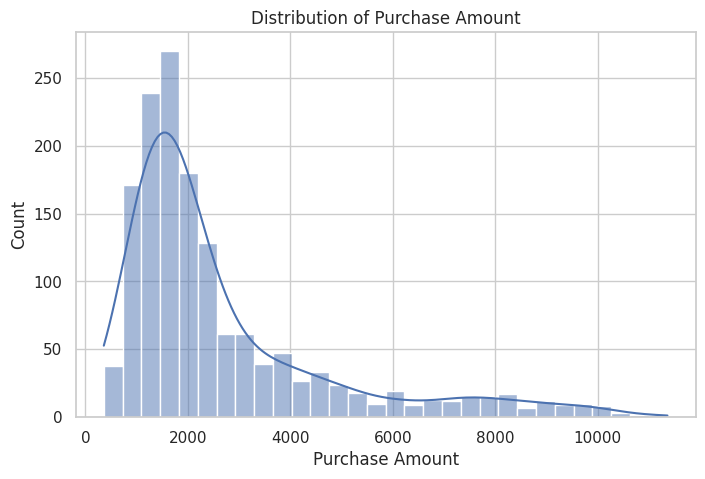

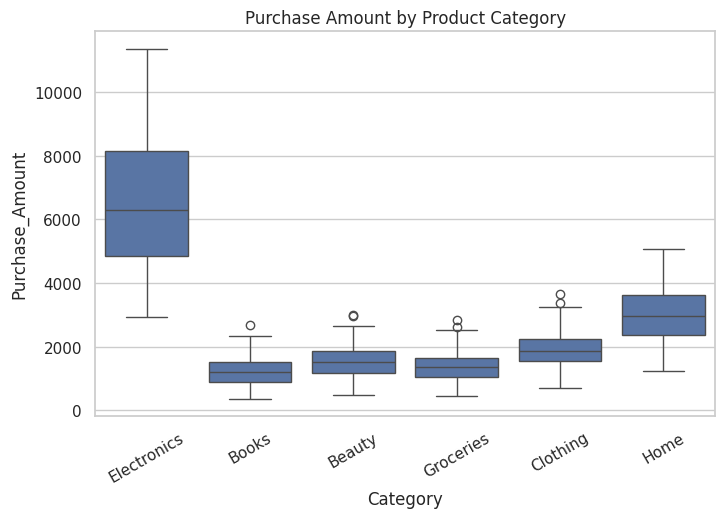

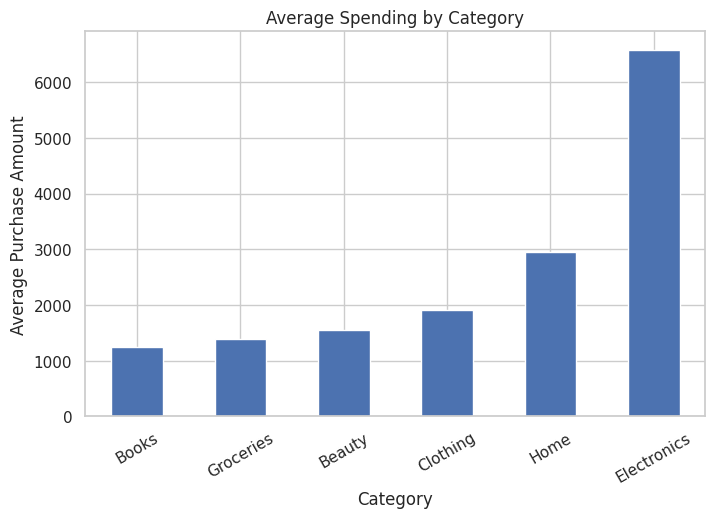

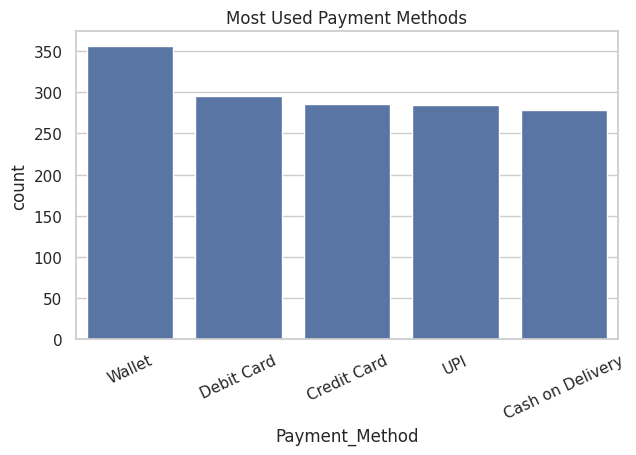

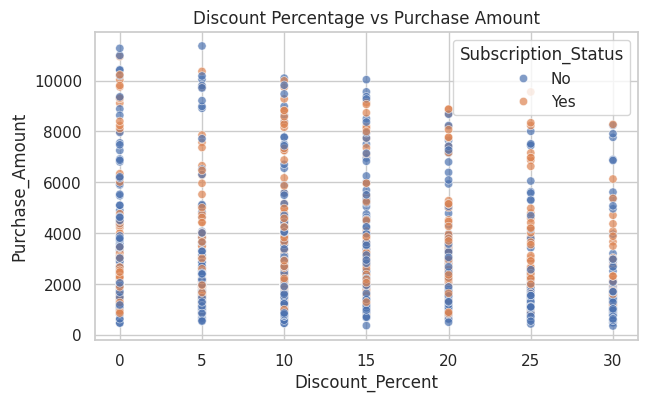

In [5]:
sns.set_theme(style="whitegrid")

plt.figure(figsize=(8, 5))
sns.histplot(data["Purchase_Amount"], bins=30, kde=True)
plt.title("Distribution of Purchase Amount")
plt.xlabel("Purchase Amount")
plt.show()

plt.figure(figsize=(8, 5))
sns.boxplot(data=data, x="Category", y="Purchase_Amount")
plt.title("Purchase Amount by Product Category")
plt.xticks(rotation=30)
plt.show()

plt.figure(figsize=(8, 5))
data.groupby("Category")["Purchase_Amount"].mean().sort_values().plot(kind="bar")
plt.title("Average Spending by Category")
plt.ylabel("Average Purchase Amount")
plt.xticks(rotation=30)
plt.show()

plt.figure(figsize=(7, 4))
sns.countplot(data=data, x="Payment_Method", order=data["Payment_Method"].value_counts().index)
plt.title("Most Used Payment Methods")
plt.xticks(rotation=25)
plt.show()

plt.figure(figsize=(7, 4))
sns.scatterplot(data=data, x="Discount_Percent", y="Purchase_Amount", hue="Subscription_Status", alpha=0.7)
plt.title("Discount Percentage vs Purchase Amount")
plt.show()

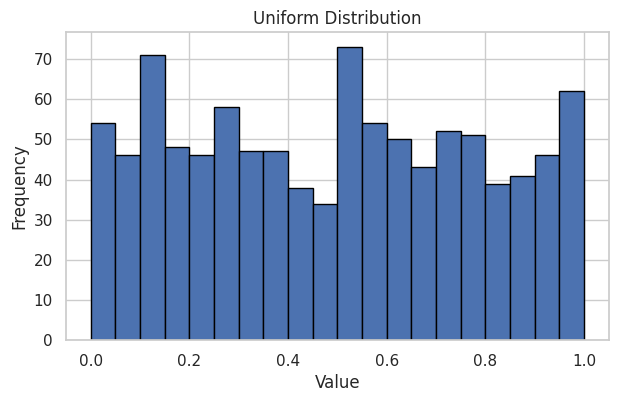

Binomial P(X >= 3) for n=5, p=0.5: 0.5


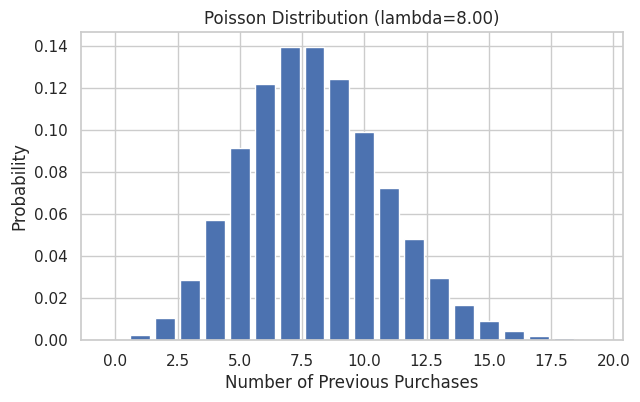

In [6]:
# Uniform distribution example: random values between 0 and 1
uniform_values = np.random.uniform(0, 1, 1000)
plt.figure(figsize=(7, 4))
plt.hist(uniform_values, bins=20, edgecolor="black")
plt.title("Uniform Distribution")
plt.xlabel("Value")
plt.ylabel("Frequency")
plt.show()

# Binomial distribution: probability that a customer buys 3 or more items
# Treat each item opportunity as a success with probability p=0.5, n=5
from scipy.stats import binom, poisson

n_trials, p_success = 5, 0.5
prob_3_or_more = 1 - binom.cdf(2, n_trials, p_success)
print("Binomial P(X >= 3) for n=5, p=0.5:", round(prob_3_or_more, 4))

# Poisson distribution: number of previous purchases, using observed average as lambda
lam = data["Previous_Purchases"].mean()
x = np.arange(0, 20)
plt.figure(figsize=(7, 4))
plt.bar(x, poisson.pmf(x, lam))
plt.title(f"Poisson Distribution (lambda={lam:.2f})")
plt.xlabel("Number of Previous Purchases")
plt.ylabel("Probability")
plt.show()

In [7]:
# Sampling techniques: simple random, systematic, stratified, and cluster samples
sample_size = min(100, len(data))

simple_random = data.sample(n=sample_size, random_state=42)

step = max(1, len(data) // sample_size)
systematic = data.iloc[::step].head(sample_size)

stratified = (data.groupby("Category", group_keys=False)
              .apply(lambda group: group.sample(
                  n=max(1, round(sample_size * len(group) / len(data))),
                  random_state=42)))
stratified = stratified.head(sample_size)

# Cluster sampling: randomly select one or more location groups
chosen_locations = data["Location"].drop_duplicates().sample(
    n=min(1, data["Location"].nunique()), random_state=42
)
cluster_sample = data[data["Location"].isin(chosen_locations)]

print("Simple random sample:", simple_random.shape)
print("Systematic sample:", systematic.shape)
print("Stratified sample:", stratified.shape)
print("Cluster sample:", cluster_sample.shape)

comparison = pd.DataFrame({
    "Sample": ["Simple Random", "Systematic", "Stratified", "Cluster"],
    "Mean_Purchase_Amount": [
        simple_random["Purchase_Amount"].mean(),
        systematic["Purchase_Amount"].mean(),
        stratified["Purchase_Amount"].mean(),
        cluster_sample["Purchase_Amount"].mean()
    ]
})
display(comparison.round(2))

Simple random sample: (100, 13)
Systematic sample: (100, 13)
Stratified sample: (100, 13)
Cluster sample: (674, 13)


/tmp/ipykernel_4620/2638102789.py:10: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda group: group.sample(


,Sample,Mean_Purchase_Amount
0,Simple Random,2779.56
1,Systematic,2632.99
2,Stratified,2795.98
3,Cluster,2597.74


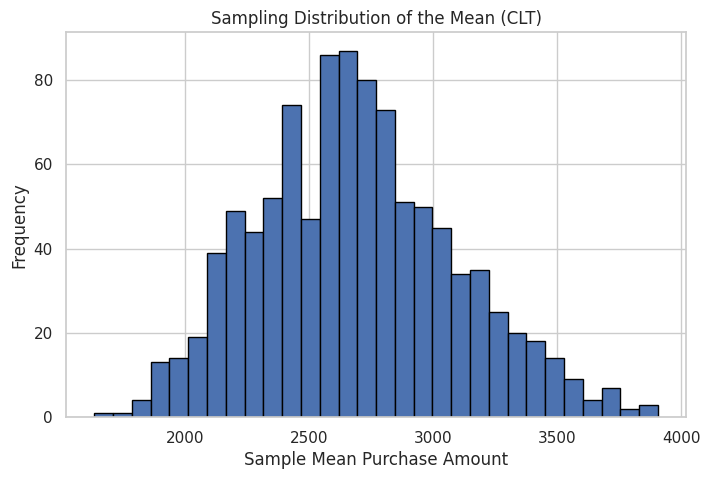

Population mean: 2682.29
Mean of sample means: 2689.91
Observed standard error: 400.14
Theoretical standard error: 388.58


In [8]:
# CLT: distribution of sample means
population = data["Purchase_Amount"].to_numpy()
sample_means = []

for _ in range(1000):
    sample = np.random.choice(population, size=30, replace=True)
    sample_means.append(sample.mean())

plt.figure(figsize=(8, 5))
plt.hist(sample_means, bins=30, edgecolor="black")
plt.title("Sampling Distribution of the Mean (CLT)")
plt.xlabel("Sample Mean Purchase Amount")
plt.ylabel("Frequency")
plt.show()

print("Population mean:", round(population.mean(), 2))
print("Mean of sample means:", round(np.mean(sample_means), 2))
print("Observed standard error:", round(np.std(sample_means, ddof=1), 2))
print("Theoretical standard error:", round(population.std(ddof=1) / np.sqrt(30), 2))

In [9]:
from scipy import stats

sample = data["Purchase_Amount"].sample(n=100, random_state=42)
confidence = 0.95
mean_value = sample.mean()
sem = stats.sem(sample)
lower, upper = stats.t.interval(confidence, df=len(sample)-1, loc=mean_value, scale=sem)

print("Sample size:", len(sample))
print("Sample mean:", round(mean_value, 2))
print("95% confidence interval: (", round(lower, 2), ",", round(upper, 2), ")")

Sample size: 100
Sample mean: 2779.56
95% confidence interval: ( 2292.13 , 3267.0 )


In [10]:
from scipy.stats import ttest_1samp

# One-sample t-test: compare average purchase with a hypothetical reference value ₹2,000
reference_mean = 2000
t_stat, p_value = ttest_1samp(data["Purchase_Amount"], popmean=reference_mean)

print("H0: Mean purchase amount equals ₹2,000")
print("H1: Mean purchase amount differs from ₹2,000")
print("t-statistic:", round(t_stat, 4))
print("p-value:", round(p_value, 6))

alpha = 0.05
if p_value < alpha:
    print("Decision: Reject H0 (statistically significant difference).")
else:
    print("Decision: Fail to reject H0 (insufficient evidence of a difference).")

H0: Mean purchase amount equals ₹2,000
H1: Mean purchase amount differs from ₹2,000
t-statistic: 12.4156
p-value: 0.0
Decision: Reject H0 (statistically significant difference).


In [11]:
# Covariance between numerical variables
covariance_matrix = data[[
    "Age", "Purchase_Amount", "Items_Purchased",
    "Discount_Percent", "Previous_Purchases", "Review_Rating"
]].cov()
display(covariance_matrix.round(2))

print("Covariance between Items_Purchased and Purchase_Amount:",
      round(data["Items_Purchased"].cov(data["Purchase_Amount"]), 2))

,Age,Purchase_Amount,Items_Purchased,Discount_Percent,Previous_Purchases,Review_Rating
Age,188.60,-400.03,0.05,-10.81,0.34,0.35
Purchase_Amount,-400.03,4529948.58,693.37,-2131.29,-98.22,-22.11
Items_Purchased,0.05,693.37,4.07,0.43,0.00,0.01
Discount_Percent,-10.81,-2131.29,0.43,81.84,-0.78,0.04
Previous_Purchases,0.34,-98.22,0.00,-0.78,7.82,0.11
Review_Rating,0.35,-22.11,0.01,0.04,0.11,0.58


Covariance between Items_Purchased and Purchase_Amount: 693.37


Pearson correlation coefficient: -0.1107
Pearson p-value: 1.7e-05
Spearman correlation coefficient: -0.12
Spearman p-value: 3e-06


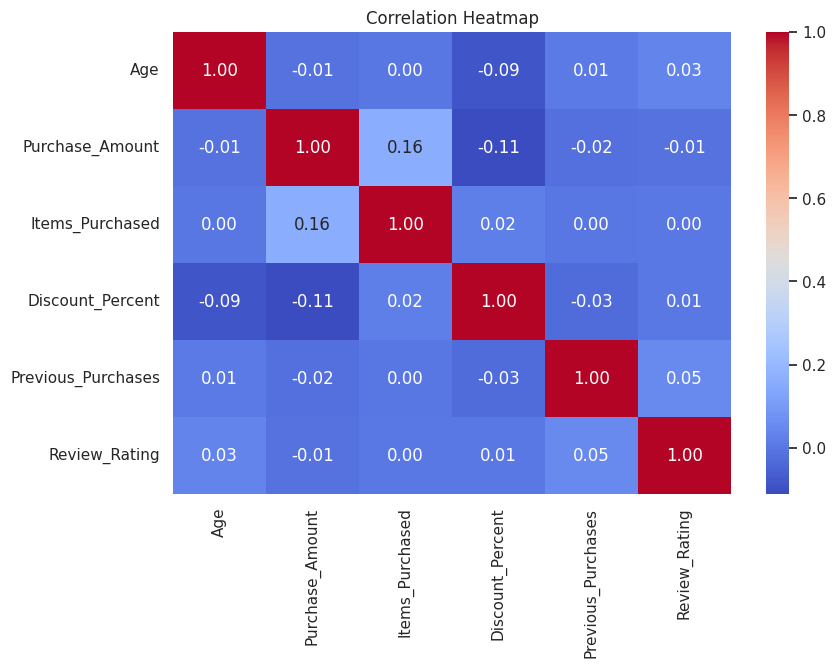

In [12]:
pearson_r, pearson_p = stats.pearsonr(data["Discount_Percent"], data["Purchase_Amount"])
spearman_r, spearman_p = stats.spearmanr(data["Discount_Percent"], data["Purchase_Amount"])

print("Pearson correlation coefficient:", round(pearson_r, 4))
print("Pearson p-value:", round(pearson_p, 6))
print("Spearman correlation coefficient:", round(spearman_r, 4))
print("Spearman p-value:", round(spearman_p, 6))

corr_cols = ["Age", "Purchase_Amount", "Items_Purchased",
             "Discount_Percent", "Previous_Purchases", "Review_Rating"]
plt.figure(figsize=(9, 6))
sns.heatmap(data[corr_cols].corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

In [13]:
from scipy.stats import chi2_contingency, ttest_ind, f_oneway

# Chi-square test: subscription status vs payment method
contingency = pd.crosstab(data["Subscription_Status"], data["Payment_Method"])
chi2, chi_p, dof, expected = chi2_contingency(contingency)

print("Contingency table:")
display(contingency)
print("Chi-square statistic:", round(chi2, 4))
print("p-value:", round(chi_p, 6))
print("Degrees of freedom:", dof)
print("Interpretation:", "Association detected" if chi_p < 0.05 else "No significant association detected")

# Independent Welch t-test: purchase amount by subscription status
sub_yes = data.loc[data["Subscription_Status"] == "Yes", "Purchase_Amount"]
sub_no = data.loc[data["Subscription_Status"] == "No", "Purchase_Amount"]
t_stat, t_p = ttest_ind(sub_yes, sub_no, equal_var=False)

print("\\nWelch independent t-test: subscribed vs not subscribed")
print("t-statistic:", round(t_stat, 4))
print("p-value:", round(t_p, 6))

Contingency table:


Payment_Method,Cash on Delivery,Credit Card,Debit Card,UPI,Wallet
Subscription_Status,,,,,
No,172,168,172,169,231
Yes,107,118,123,115,125


Chi-square statistic: 4.0584
p-value: 0.398165
Degrees of freedom: 4
Interpretation: No significant association detected
\nWelch independent t-test: subscribed vs not subscribed
t-statistic: 4.1204
p-value: 4e-05


In [14]:
# One-way ANOVA: compare purchase amounts across product categories
groups = [
    group["Purchase_Amount"].to_numpy()
    for _, group in data.groupby("Category")
]
f_stat, anova_p = f_oneway(*groups)

print("ANOVA F-statistic:", round(f_stat, 4))
print("ANOVA p-value:", round(anova_p, 6))
if anova_p < 0.05:
    print("At least one category has a different mean purchase amount.")
else:
    print("No statistically significant difference among category means was detected.")

ANOVA F-statistic: 1088.7186
ANOVA p-value: 0.0
At least one category has a different mean purchase amount.


In [15]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

# Predict Purchase_Amount using the other customer/purchase features
features = [
    "Age", "Gender", "Category", "Items_Purchased", "Payment_Method",
    "Location", "Discount_Percent", "Previous_Purchases",
    "Subscription_Status", "Season", "Review_Rating"
]
X = data[features]
y = data["Purchase_Amount"]

numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(exclude=np.number).columns.tolist()

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42
)

models = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(alpha=1.0),
    "Lasso Regression": Lasso(alpha=0.01, max_iter=10000),
    "Decision Tree": DecisionTreeRegressor(max_depth=8, random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42)
}

results = []
predictions = {}
trained_pipelines = {}

for name, model in models.items():
    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", model)
    ])
    pipeline.fit(X_train, y_train)
    trained_pipelines[name] = pipeline
    pred = pipeline.predict(X_test)
    predictions[name] = pred
    results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "R2_Score": r2_score(y_test, pred)
    })

results_df = pd.DataFrame(results).sort_values("RMSE")
display(results_df.round(3))

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.295e+07, tolerance: 5.172e+05
  model = cd_fast.enet_coordinate_descent(


,Model,MAE,RMSE,R2_Score
1,Ridge Regression,619.470,951.484,0.790
2,Lasso Regression,620.038,952.746,0.789
0,Linear Regression,620.049,952.758,0.789
4,Random Forest,634.285,976.666,0.779
3,Decision Tree,722.453,1264.667,0.629


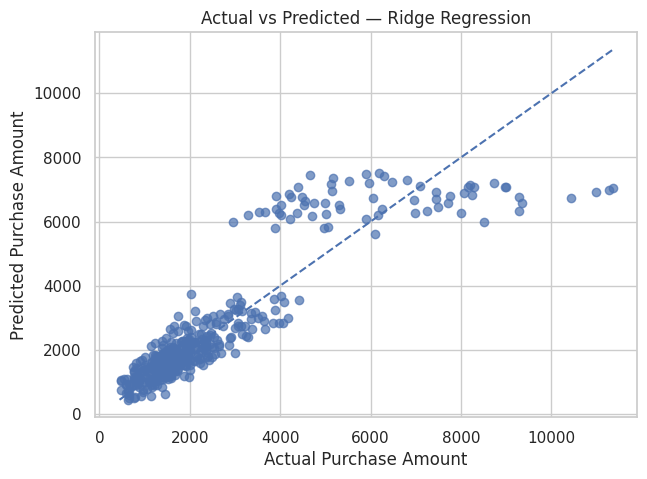

Best model by RMSE: Ridge Regression
MAE: 619.47
RMSE: 951.48
R² score: 0.79


In [16]:
best_model_name = results_df.iloc[0]["Model"]
best_predictions = predictions[best_model_name]

plt.figure(figsize=(7, 5))
plt.scatter(y_test, best_predictions, alpha=0.7)
minimum = min(y_test.min(), best_predictions.min())
maximum = max(y_test.max(), best_predictions.max())
plt.plot([minimum, maximum], [minimum, maximum], linestyle="--")
plt.xlabel("Actual Purchase Amount")
plt.ylabel("Predicted Purchase Amount")
plt.title(f"Actual vs Predicted — {best_model_name}")
plt.show()

print("Best model by RMSE:", best_model_name)
print("MAE:", round(mean_absolute_error(y_test, best_predictions), 2))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test, best_predictions)), 2))
print("R² score:", round(r2_score(y_test, best_predictions), 4))

In [17]:
!pip -q install gradio

In [18]:
import gradio as gr

# The first tab summarizes records already present in the dataset.
def spending_summary(category_choice, subscription_choice, location_choice):
    filtered = data.copy()
    if category_choice != "All":
        filtered = filtered[filtered["Category"] == category_choice]
    if subscription_choice != "All":
        filtered = filtered[filtered["Subscription_Status"] == subscription_choice]
    if location_choice != "All":
        filtered = filtered[filtered["Location"] == location_choice]

    if filtered.empty:
        return "No records match these filters.", None

    summary_text = (
        "EXISTING DATA SUMMARY (not a prediction)\n"
        f"Number of matching records: {len(filtered)}\n"
        f"Average purchase amount: ₹{filtered['Purchase_Amount'].mean():,.2f}\n"
        f"Median purchase amount: ₹{filtered['Purchase_Amount'].median():,.2f}\n"
        f"Total spending in matching records: ₹{filtered['Purchase_Amount'].sum():,.2f}\n"
        f"Average items purchased: {filtered['Items_Purchased'].mean():.2f}\n"
        f"Average review rating: {filtered['Review_Rating'].mean():.2f}/5"
    )

    fig, ax = plt.subplots(figsize=(7, 4))
    filtered.groupby("Category")["Purchase_Amount"].mean().sort_values().plot(kind="bar", ax=ax)
    ax.set_title("Average Purchase Amount by Category (existing records)")
    ax.set_ylabel("Average Purchase Amount (₹)")
    ax.set_xlabel("Category")
    plt.xticks(rotation=30)
    plt.tight_layout()
    return summary_text, fig

# Select the model with the lowest test RMSE from the comparison above.
best_model_name = results_df.iloc[0]["Model"]
best_pipeline = trained_pipelines[best_model_name]

# This function predicts an estimated purchase amount for a new input row.
def predict_purchase_amount(age, gender, category, items_purchased, payment_method,
                            location, discount_percent, previous_purchases,
                            subscription_status, season, review_rating):
    new_customer = pd.DataFrame([{
        "Age": age,
        "Gender": gender,
        "Category": category,
        "Items_Purchased": items_purchased,
        "Payment_Method": payment_method,
        "Location": location,
        "Discount_Percent": discount_percent,
        "Previous_Purchases": previous_purchases,
        "Subscription_Status": subscription_status,
        "Season": season,
        "Review_Rating": review_rating
    }], columns=features)

    predicted_amount = float(best_pipeline.predict(new_customer)[0])
    return (
        f"Estimated purchase amount: ₹{predicted_amount:,.2f}\n"
        f"Model used: {best_model_name}\n\n"
        "This is a model prediction for the input values, not a value looked up from a matching dataset row. "
        "The dataset is synthetic, so this estimate is for demonstration and should not be treated as a real-world forecast."
    )

categories = sorted(data["Category"].dropna().unique().tolist())
payment_methods = sorted(data["Payment_Method"].dropna().unique().tolist())
locations = sorted(data["Location"].dropna().unique().tolist())
seasons = sorted(data["Season"].dropna().unique().tolist())

with gr.Blocks(title="Online Shopping Spending Pattern Analysis") as demo:
    gr.Markdown("# Online Shopping Spending Pattern Analysis")
    gr.Markdown("Use **Spending Summary** to explore existing dataset records. Use **Predict Purchase Amount** to get a new estimate from the trained regression model.")

    with gr.Tab("Spending Summary — Existing Data"):
        gr.Markdown("These statistics are calculated from records already in the dataset; they are not predictions.")
        with gr.Row():
            category_filter = gr.Dropdown(["All"] + categories, value="All", label="Category")
            subscription_filter = gr.Dropdown(["All", "Yes", "No"], value="All", label="Subscription Status")
            location_filter = gr.Dropdown(["All"] + locations, value="All", label="Location")
        summary_button = gr.Button("Show Spending Summary")
        summary_output = gr.Textbox(label="Spending Summary", lines=7)
        chart_output = gr.Plot(label="Average Purchase Amount by Category")
        summary_button.click(
            fn=spending_summary,
            inputs=[category_filter, subscription_filter, location_filter],
            outputs=[summary_output, chart_output]
        )

    with gr.Tab("Predict Purchase Amount — New Input"):
        gr.Markdown(f"The selected model is **{best_model_name}**, chosen because it had the lowest RMSE on the held-out test set.")
        gr.Markdown("Enter a hypothetical customer/purchase profile. All fields below are inputs to the trained model.")
        with gr.Row():
            age_input = gr.Slider(18, 65, value=28, step=1, label="Age")
            gender_input = gr.Dropdown(["Female", "Male", "Other"], value="Female", label="Gender")
            category_input = gr.Dropdown(categories, value=categories[0], label="Category")
        with gr.Row():
            items_input = gr.Slider(1, 7, value=3, step=1, label="Items Purchased")
            payment_input = gr.Dropdown(payment_methods, value=payment_methods[0], label="Payment Method")
            location_input = gr.Dropdown(locations, value=locations[0], label="Location")
        with gr.Row():
            discount_input = gr.Dropdown([0, 5, 10, 15, 20, 25, 30], value=10, label="Discount Percent")
            previous_input = gr.Slider(0, 30, value=5, step=1, label="Previous Purchases")
            subscription_input = gr.Dropdown(["Yes", "No"], value="No", label="Subscription Status")
        with gr.Row():
            season_input = gr.Dropdown(seasons, value=seasons[0], label="Season")
            rating_input = gr.Slider(1, 5, value=4.0, step=0.1, label="Review Rating")
        predict_button = gr.Button("Predict Purchase Amount")
        prediction_output = gr.Textbox(label="Model Prediction", lines=5)
        predict_button.click(
            fn=predict_purchase_amount,
            inputs=[age_input, gender_input, category_input, items_input, payment_input,
                    location_input, discount_input, previous_input, subscription_input,
                    season_input, rating_input],
            outputs=prediction_output
        )

demo.launch(share=True)


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://e1f8556dde302a8b11.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
